# Week 2 - click an object -> mask -> track -> rebuild -> hand-off (Person A)
**Settings:** Accelerator = *GPU T4 x2* - Internet = *On*.

**Why a separate notebook from Week 1:** Week 1 costs ~1 h of GPU (poses + training) and is done once. Week 2 is
interactive - you try objects, fix clicks, re-run tracking - so it starts from the saved Week 1 files
(`demo_week2_inputs.zip`, built at the end of the Week 1 notebook) instead of redoing them. Different models too (SAM 2.1).

**Inputs:** add the Week 1 notebook's output (or a dataset containing `demo_week2_inputs.zip`) via *Add Input*.
**Output:** `handoff_demo.zip` for Person B and Person C (data + generated READMEs + numbers).

In [1]:
# 0. Code: clone your repo OR copy it from a Kaggle dataset (same as the Week 1 notebook)
# !git clone https://github.com/<your-team>/<your-repo>.git /kaggle/working/repo
!cp -r /kaggle/input/datasets/shahdelsawy/full-w12/week1_pipeline /kaggle/working/
%cd /kaggle/working/week1_pipeline

/kaggle/working/week1_pipeline


In [2]:
# 1. Setup: gsplat (rebuild) + SAM 2.1 (masks). No VGGT / pycolmap needed here.  ~5-10 min
!bash scripts/setup_kaggle.sh w2

=== base python deps ===
ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
=== gsplat + examples ===
python: /usr/local/bin/python
gsplat version: 1.5.3
Note: switching to '937e29912570c372bed6747a5c9bf85fed877bae'.
You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.
If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:
  git switch -c <new-branch-name>
Or undo this operation with:
  git switch -
Turn off this advice by setting config variable advice.detachedHead to false
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
gsplat 1.5.3 cuda True
fused_ssim OK
fused_bilagrid OK
=== S

In [3]:
# 2. Environment + unpack the Week 1 results into the workspace
import os, re, shutil, glob
for line in open("/kaggle/working/env.sh"):
    m = re.match(r"export (\w+)=(.*)", line.strip())
    if m: os.environ[m.group(1)] = os.path.expandvars(m.group(2))
os.environ["PATH"] = ":".join(x for x in os.environ["PATH"].split(":") if x and "/kaggle/working/cm/bin" not in x and "$PATH" not in x)
os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5"
os.environ["W1_ROOT"] = "/kaggle/working/workspace"
os.environ["W1_PROJECT"] = "demo"
P = os.environ["W1_ROOT"] + "/demo"
INPUT_PATH = "/kaggle/input/datasets/shahdelsawy/2nd-input"
os.makedirs(P, exist_ok=True)

if os.path.isdir(INPUT_PATH):
    # dataset folder: copy contents (or unzip a zip inside it, if there is one)
    zips = glob.glob(f"{INPUT_PATH}/**/demo_week2_inputs.zip", recursive=True)
    if zips:
        !unzip -q -o "{zips[0]}" -d $P
    else:
        !cp -r "$INPUT_PATH"/* "$P"/
else:
    !unzip -q -o "$INPUT_PATH" -d $P

import json
d = json.load(open(f"{P}/week2/inputs.json"))
print("frames:", d["registered_frames"], "| checkpoint:", d["checkpoint"])
d = json.load(open(f"{P}/week2/inputs.json"))
print("pose method:", d["pose_method"], "| frames:", d["registered_frames"], "/", d["total_frames"], "| same image space:",
      d["images"]["same_pixels"], "| depth:", d["depth"]["kind"], "| checkpoint:", d["checkpoint"])

frames: 61 | checkpoint: gs/gsplat_30000/ckpts/ckpt_29999_rank0.pt
pose method: glomap | frames: 61 / 61 | same image space: True | depth: splat_rendered | checkpoint: gs/gsplat_30000/ckpts/ckpt_29999_rank0.pt


## 2b. Calibrate: make the splat checkpoint and the poses agree (REQUIRED)
gsplat trains in a *normalized* world space by default, so rendering the checkpoint with raw COLMAP poses gives garbage
(Week 2 first run: fine-tune PSNR 8 instead of ~26, 3D lift found nothing). This cell tests both pose sets on a few photos,
keeps the one that reproduces them, and re-renders the splat depth. Expect: right set ~25 dB, wrong set ~8 dB.

In [4]:
!python stages/w2_calibrate.py --project-dir $P

[calibrate] normalized poses unavailable: ModuleNotFoundError: No module named 'datasets.colmap'
( ●    ) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes
(  ●   ) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes
(   ●  ) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes
(    ● ) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes
(     ●) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes
(    ● ) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes
(   ●  ) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes
(  ●   ) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes
( ●    ) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes
(●     ) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes
( ●    ) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes
(  ●   ) gsplat: Setting up CUDA w

In [5]:
# 3. GPU self-test (2 min): SAM 2 image+video, gsplat API, fused-ssim, a 20-step fine-tune on YOUR scene.
#    If something FAILs, send me the printed line - it is the exact API/dtype problem.
!python tools/w2_selftest.py --project-dir $P --finetune-steps 20

[finetune] step 0/20 loss 0.5091 gaussians 1488141
[finetune] step 10/20 loss 0.4850 gaussians 1488141
[finetune] step 19/20 loss 0.5160 gaussians 1488141
== Week 2 self-test ==
  PASS  cuda: Tesla T4, torch 2.11.0+cu130, 2 GPU(s) (1.7s)
  PASS  sam2 image model + one click: mask 52593 px, score 0.75 (14.8s)
  PASS  sam2 video model loads: loaded (2.2s)
  PASS  gsplat + strategy API + fused-ssim: render (1, 200, 200, 3), depth (1, 200, 200, 1); fused_ssim ok (0.2s)
  PASS  fine-tune loop (few steps on the real scene): 20 steps, 1.3s, held-out PSNR 8.23, peak 1.82 GB (3.3s)


## A. Pick the object (click -> mask)
Run the next cell, read the pixel coordinates off the axes, put them in `CLICKS` (x right, y down, in pixels of the shown frame).
`positive: false` = "not this" (use it to cut the mask off a neighbouring object).

61 frames: 000001.jpg ... 000061.jpg


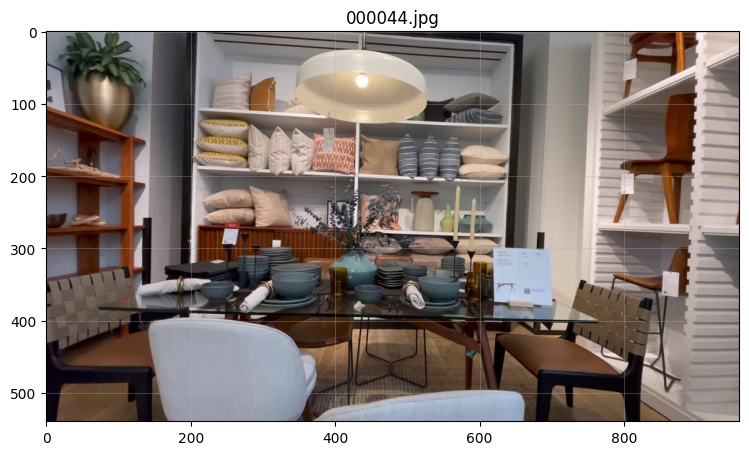

In [6]:
import json, cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
names = sorted(p.name for p in Path(P, "frames/images").glob("*.jpg"))
print(len(names), "frames:", names[0], "...", names[-1])
def show(name, clicks=None, mask_sub=None, size=9):
    img = cv2.cvtColor(cv2.imread(f"{P}/frames/images/{name}"), cv2.COLOR_BGR2RGB)
    if mask_sub:
        mp = Path(P, "edits", EDIT, mask_sub, Path(name).stem + ".png")
        if mp.exists():
            m = cv2.imread(str(mp), 0) > 127
            img = img.copy(); img[m] = (0.5 * img[m] + 0.5 * np.array([0, 255, 0])).astype(np.uint8)
    plt.figure(figsize=(size, size * img.shape[0] / img.shape[1])); plt.imshow(img)
    for c in clicks or []:
        plt.scatter(c["x"], c["y"], c="lime" if c.get("positive", True) else "red", s=120, edgecolors="k")
    plt.grid(alpha=.3); plt.title(name); plt.show()
EDIT = "e1"
REF = names[43]                      # <- the frame you click on (000044: grey-blue chair large + clear); the SAME variable feeds show() and the segmenting
show(REF)

In [7]:
import os, json, cv2
from pathlib import Path

P = "/kaggle/working/workspace/demo"          # the unpacked project (NOT /kaggle/input/...)
EDIT = "e1"
REF = "000044.jpg"
os.environ.update(W1_ROOT="/kaggle/working/workspace", W1_PROJECT="demo")

assert os.path.isdir(f"{P}/frames/images"), "run the unpack cell first: it copies the dataset into /kaggle/working/workspace/demo"
print(len(os.listdir(f"{P}/frames/images")), "frames; REF exists:", os.path.exists(f"{P}/frames/images/{REF}"))

61 frames; REF exists: True


[w2_segment] [('000044.jpg', 28268, 0.9819)]


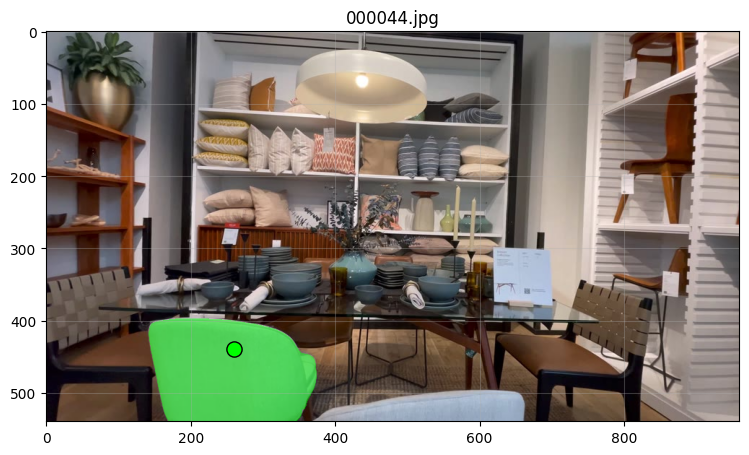

mask area px: 28268


In [8]:
# 4. Segment: your clicks -> mask on REF.  Edit CLICKS and re-run until the mask is right.
CLICKS = [{"x": 260, "y": 440, "positive": True}]
!python stages/w2_segment.py --project-dir {P} --edit-id {EDIT} --frame {REF} --clicks '{json.dumps(CLICKS)}'
show(REF, CLICKS, "masks")
# Guard: the mask of REF must exist and be plausible, otherwise STOP (a wrong --frame once made a 2k px mask on another frame)
mp = Path(P, "edits", EDIT, "masks", Path(REF).stem + ".png")
assert mp.exists(), f"no mask for {REF}: the clicks were segmented on another frame"
area = int((cv2.imread(str(mp), 0) > 127).sum()); print("mask area px:", area)
assert area > 3000, "mask is tiny - wrong object? move/add clicks"

## B. Track it through the video
Default = **both** methods fused (SAM 2 video propagation + 3D lift with visibility check, SAM 2 refines the edges).
Green = your click, orange = SAM 2 propagation, blue = lifted from 3D, red border = object not in that frame.

In [9]:
# simplest first (PDF 4.2): SAM 2 alone. Check the grid, THEN set TRACKER = "both" to add the 3D lift.
TRACKER = "sam2"          # sam2 | both | lift
!python stages/w2_track.py --project-dir $P --edit-id $EDIT --tracker $TRACKER
!python tools/w2_preview.py --project-dir $P --edit-id $EDIT --cols 6
from IPython.display import Image, display
display(Image(f"{P}/edits/{EDIT}/preview_masks.png"))

/usr/local/lib/python3.13/dist-packages/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/usr/local/lib/python3.13/dist-packages/sam2/__init__.py)
Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although so

<IPython.core.display.Image object>

In [10]:
# 5. FALLBACK (spec 4.4): frames where tracking missed the object -> mark them yourself, then re-run track.
#    Each marked frame becomes a new anchor ("user"), so the next tracking pass is better everywhere.
FIX = []      # e.g. [{"name": "000030.jpg", "clicks": [{"x": 300, "y": 200, "positive": True}]}]
if FIX:
    !python stages/w2_segment.py --project-dir $P --edit-id $EDIT --add-frames '{json.dumps(FIX)}'
    !python stages/w2_track.py --project-dir $P --edit-id $EDIT --tracker both
    !python tools/w2_preview.py --project-dir $P --edit-id $EDIT --cols 6
    display(Image(f"{P}/edits/{EDIT}/preview_masks.png"))

## C. Evaluate the tracking (this table goes in the report)
Label 10-30 frames spread over the video: either clicks on the object (SAM builds the mask) or `{"absent": true}` where the object
is not visible. Then the three methods are compared on those frames.

In [11]:
GT = {   # <- edit: frame -> clicks | {"absent": true}
    # "000010.jpg": {"clicks": [{"x": 400, "y": 250, "positive": True}]},
    # "000055.jpg": {"absent": True},
}
json.dump(GT, open(f"{P}/edits/{EDIT}/gt.json", "w"))
if GT:
    !python stages/w2_track.py --project-dir $P --edit-id $EDIT --tracker sam2 --out track_eval/sam2/masks
    !python stages/w2_track.py --project-dir $P --edit-id $EDIT --tracker lift --out track_eval/lift/masks
    !python tools/w2_eval_tracking.py --project-dir $P --edit-id $EDIT --gt $P/edits/$EDIT/gt.json --variants sam2 lift both

## C2. Diffusion edit (Qwen-Image-2.1): reference frame first, then every other frame
Uses the masks from A-B. Writes `edits/<id>/edited/` (what section D reads), so if you run this, **skip the fake-edit cell in D**.
Run it after sections A-C: the install upgrades `transformers`, which SAM 2 and gsplat do not use. It needs the Hugging Face token as a Kaggle
secret named `HF_TOKEN` if the model download asks for login. One GPU (`--gpu 0`), one process, 4-bit by default.

In [12]:
!bash scripts/setup_kaggle.sh diffusion
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
except Exception as e:
    print("no HF_TOKEN secret (fine if the model downloads without login):", type(e).__name__)

=== Diffusion editing (Week 2): Qwen-Image-2.1 via diffusers + bitsandbytes ===
Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
diffusion OK | torch 2.11.0+cu130 | transformers 5.23.0 | diffusers 0.43.0 | bitsandbytes 0.50.2 | cuda True
Qwen-Image-2.1 weights (~40 GB download) come from the Hugging Face hub at first use; license: Qwen Research (non-commercial).
=== done. Next: source /kaggle/working/env.sh ===
no HF_TOKEN secret (fine if the model downloads without login): BackendError


Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Reconstructing (incomplete total...): |            |  0.00B /  0.00B
Reconstructing (incomplete total...):   0%|        |  0.00B / 5.29kB
Reconstructing (incomplete total...):   0%|        | 5.29kB / 11.4MB
Reconstructing (incomplete total...):   0%|        | 5.29kB / 13.1MB
Reconstructing (incomplete total...):   0%|        | 5.91kB / 13.1MB
Reconstructing (incomplete total...):   0%|        | 12.1kB / 15.9MB
Reconstructing (incomplete total...):   0%|        | 13.7kB / 5.01GB
Reconstructing (incomplete total...):   0%|        | 13.7kB / 9.93GB
Reconstructing (incomplete total...):   0%|    

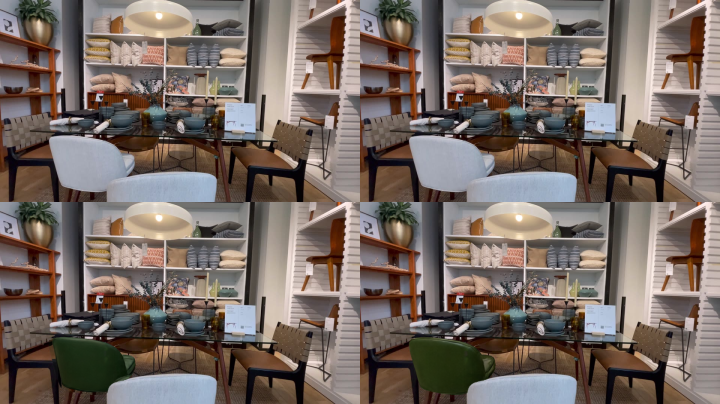

In [13]:
# 1. Several seeds on the frame where the object is large and fully visible. Look at the sheet and pick the best seed.
PROMPT = "Change the light grey-blue upholstered chair into a dark green leather chair. Keep the exact same chair shape, size and position, with realistic leather sheen matching the room lighting."   # this room has no sofa
!python stages/w2_edit.py --project-dir $P --edit-id $EDIT --phase reference --prompt "{PROMPT}" --n-seeds 2 --gen-scale 0.7 --offload model
display(Image(f"{P}/edits/{EDIT}/preview_reference.png"))

In [14]:
!ls -R {P}/edits/{EDIT} | head -60
!tail -30 {P}/edits/{EDIT}/metrics/*.log 2>/dev/null

/kaggle/working/workspace/demo/edits/e1:
edit
gt.json
masks
metrics
preview_masks.png
preview_reference.png
/kaggle/working/workspace/demo/edits/e1/edit:
reference
/kaggle/working/workspace/demo/edits/e1/edit/reference:
index.json
seed_0.png
seed_1.png
/kaggle/working/workspace/demo/edits/e1/masks:
000017.png
... [6 lines omitted by clean_notebook.py] ...
000036.png
000037.png
000038.png
000039.png
000040.png
000041.png
000042.png
000043.png
000044.png
000045.png
000046.png
000047.png
000048.png
000049.png
000050.png
000051.png
000052.png
000053.png
000054.png
000055.png
000056.png
000057.png
index.json
/kaggle/working/workspace/demo/edits/e1/metrics:
progress.jsonl
track_debug.json
w2_edit_4bit_bfloat16_model_s40.json
w2_edit.json
w2_segment.json
w2_track.json


In [15]:
# 2. Every other frame: its own mask, the same prompt, the chosen reference edit as an extra condition image.
#    Smoke test first: add  --limit 2  to edit only two frames and check the sheet before the full run.
REF_SEED = 0          # <- the seed you picked (the first candidate is seed 0)
!python stages/w2_edit.py --project-dir $P --edit-id $EDIT --phase rest --ref-seed $REF_SEED --prompt "{PROMPT}" --gen-scale 0.7 --offload model
display(Image(f"{P}/edits/{EDIT}/preview_edited.png"))

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Traceback (most recent call last):
  File "/kaggle/working/week1_pipeline/common/diffusion_edit.py", line 263, in edit
    out = self.pipe(**kw).images[0]
          ~~~~~~~~~^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/_contextlib.py", line 124, in decorate_context
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/qwenimage21/pipeline_qwenimage21.py", line 784, in __call__
    noise_pred = self.transformer(
                 ~~~~~~~~~~~~~~~~^
        hidden_states=latent_model_input,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

FileNotFoundError: No such file or directory: '/kaggle/working/workspace/demo/edits/e1/preview_edited.png'

FileNotFoundError: No such file or directory: '/kaggle/working/workspace/demo/edits/e1/preview_edited.png'

<IPython.core.display.Image object>

In [16]:
# 3. VRAM + seconds per frame for this quantization setting. Repeat step 2 with  --quant 8bit  or
#    --quant none --offload model  (and --tag) to fill more rows; the table below collects every run.
!python tools/w2_edit_table.py --project-dir $P --edit-id $EDIT

| setting | model | quantization | dtype | offload | steps | load time | s/frame (mean) | s/frame (median) | peak VRAM (nvidia-smi, GPU delta) | peak VRAM generating (torch) | VRAM after load (torch) | frames | max pixel change outside the mask |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 4bit_bfloat16_model_s40 | Qwen/Qwen-Image-2.1 | 4bit | bfloat16 | model | 40 | 300 s | 427.2 s | 427.2 s | 12041 MiB | 11554 MiB | 10261 MiB | None | 0 |
[w2_edit_table] wrote /kaggle/working/workspace/demo/edits/e1/metrics/diffusion_table.md


## D. Rebuild (Person C + A): fine-tune vs from scratch
The diffusion edit is Person B's. Until their `edited/` frames arrive, make a **fake edit** (recolour the object) to exercise the
whole chain. To use B's real edit instead: copy their `edits/<id>/edited/` folder (PNGs + `index.json`) into `$P/edits/$EDIT/` and skip the fake cell.

In [17]:
!python tools/w2_make_test_edit.py --project-dir $P --edit-id $EDIT --color 0,0,255

[test-edit] wrote 29 edited frames to edits/e1/edited/


In [18]:
# fine-tune: start from the trained Gaussians (needs gs/ checkpoint) - minutes
!python stages/w2_rebuild.py --project-dir $P --edit-id $EDIT --mode finetune --iters 3000

[w2_rebuild] scene ready: {'edited_frames': 29, 'outside_mask_max_abs_diff': 4, 'outside_mask_mean_abs_diff': 0.166, 'outside_mask_share_diff_gt2': 0.001225}
[finetune] step 0/3000 loss 0.5010 gaussians 1488141
[finetune] step 250/3000 loss 0.3802 gaussians 1397344
[finetune] step 500/3000 loss 0.4445 gaussians 1438626
[finetune] step 750/3000 loss 0.3681 gaussians 1465371
[finetune] step 1000/3000 loss 0.5606 gaussians 1513741
[finetune] step 1250/3000 loss 0.5274 gaussians 1542908
[finetune] step 1500/3000 loss 0.2009 gaussians 1593616
[finetune] step 1750/3000 loss 0.4419 gaussians 1617138
[finetune] step 2000/3000 loss 0.2051 gaussians 1649640
[finetune] step 2250/3000 loss 0.3857 gaussians 1649640
[finetune] step 2500/3000 loss 0.5017 gaussians 1649640
[finetune] step 2750/3000 loss 0.3676 gaussians 1649640
[finetune] step 2999/3000 loss 0.3264 gaussians 1649640
$ /usr/bin/python3 /kaggle/working/week1_pipeline/stages/s5_export_splat.py --root /kaggle/working/workspace/demo/edits 

In [19]:
# from scratch: train again on the edited scene (same iterations as Week 1 quick) - the slow baseline to compare against
!python stages/w2_rebuild.py --project-dir $P --edit-id $EDIT --mode scratch --iters 7000

[w2_rebuild] scene ready: {'edited_frames': 29, 'outside_mask_max_abs_diff': 4, 'outside_mask_mean_abs_diff': 0.166, 'outside_mask_share_diff_gt2': 0.001225}
$ /usr/bin/python3 /kaggle/working/week1_pipeline/stages/s4_train_3dgs.py --root /kaggle/working/workspace/demo/edits --project e1 --trainer gsplat --mode custom --iters 7000 --holdout-every 8 --gpu 0
[train] created /kaggle/working/gsplat/examples/datasets/__init__.py (avoids clash with Hugging Face 'datasets')
[train] patched /usr/local/lib/python3.13/dist-packages/pycolmap/scene_manager.py for numpy>=2 (np.uint64(-1))
[train] gsplat 7000 iters in 9.8 min; 1336449 Gaussians; held-out {'psnr': 25.8193302154541, 'ssim': 0.8797032833099365, 'lpips': 0.07621623575687408}
$ /usr/bin/python3 /kaggle/working/week1_pipeline/stages/s5_export_splat.py --root /kaggle/working/workspace/demo/edits --project e1
[export] 1,336,449 Gaussians; ply 300.79 MB, splat 40.79 MB
[w2_rebuild] scratch: {'prepare_scene': 1.6, 'train': 589.9, 'export': 3.

## E. Hand-off for Person B and Person C

In [20]:
!python tools/make_handoff.py --project-dir $P --out /kaggle/working/handoff_demo.zip --no-checkpoint
!cat $P/edits/$EDIT/metrics/rebuild_comparison.md
!unzip -l /kaggle/working/handoff_demo.zip | tail -3
# Download handoff_demo.zip from the Output tab and send it to B and C. SUMMARY.md inside has every number.

[handoff] /kaggle/working/handoff_demo.zip  (1040.0 MB, 350 files + HANDOFF/*.md)
| mode | iterations | training time | total time | Gaussians | held-out PSNR (edited scene) | SSIM | PSNR of the ORIGINAL splat on the original frames |
|---|---|---|---|---|---|---|---|
| scratch | 7000 | 590 s | 595 s | 1336449 | 25.82 | 0.880 | 26.78 |
| finetune | 3000 | 178 s | 183 s | 1649640 | 10.55 | 0.381 | 26.78 |
     1273  2026-11-14 01:37   demo/HANDOFF/README_FOR_C.md
---------                     -------
1275637370                     353 files


In [21]:
import json
m = json.load(open(f"{P}/edits/{EDIT}/masks/index.json"))
present = sorted(f["name"] for f in m["frames"] if f["present"])
done = sorted(e["name"] for e in json.load(open(f"{P}/edits/{EDIT}/edited/index.json"))["edited"])
print(len(present), "masked frames;", len(done), "edited")
print("missing:", sorted(set(present) - set(done)))

29 masked frames; 29 edited
missing: []


In [22]:
import os
from IPython.display import FileLink, display

os.chdir('/kaggle/working')

print(os.listdir('.'))

['workspace', 'handoff_demo.zip', 'env.sh', 'week1_pipeline', 'gsplat', '.virtual_documents']


In [23]:
from IPython.display import FileLink, display

display(FileLink('handoff_demo.zip'))

/kaggle/working/handoff_demo.zip

In [24]:
from IPython.display import FileLink, display

display(FileLink('/kaggle/working/workspace/demo/gs/gsplat_30000/ckpts/ckpt_29999_rank0.pt'))

/kaggle/working/workspace/demo/gs/gsplat_30000/ckpts/ckpt_29999_rank0.pt

In [25]:
import os, subprocess
subprocess.run(["zip","-qr","/kaggle/working/e1_masks_edited.zip","masks","edited"], cwd=f"{P}/edits/{EDIT}", check=True)

CompletedProcess(args=['zip', '-qr', '/kaggle/working/e1_masks_edited.zip', 'masks', 'edited'], returncode=0)

In [26]:
display(FileLink('e1_masks_edited.zip'))

/kaggle/working/e1_masks_edited.zip